# 🍪🐱 Cookie Cats 게이트 위치 A/B 테스트 분석

**목표:** 게이트를 30레벨(gate_30)에서 40레벨(gate_40)로 옮겼을 때 유저 리텐션이 달라지는지 A/B 테스트로 검증한다.

**데이터:** Kaggle Cookie Cats 모바일 게임 A/B 테스트 데이터 (90,189명)

**순서**
1. 데이터 점검: 결측치, 중복, 그룹 비율(SRM), 이상치 확인
2. 질문과 가설 정하기: 주 지표(7일 리텐션)와 보조 지표(1일 리텐션) 설정
3. 검정 고르기: 지표 형태에 맞는 검정 선택과 그 이유
4. 검정 수행: 점추정, 95% 신뢰구간, 효과크기
5. 한 걸음 더: 검정력 분석으로 이 실험이 효과를 잡을 힘이 있었는지 확인 (필요 표본 크기, MDE)
6. 최종 보고서: 출시 / 보류 / 데이터 추가 수집 중 결정과 근거, 한계

## 1. 데이터 확인 및 전처리

In [1]:
# 데이터 불러오기 및 기본점검

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare

df = pd.read_csv("cookie_cats.csv")

print("행:", df.shape[0], "/ 열:", df.shape[1])
display(df.head())

display(pd.DataFrame({
    "타입": df.dtypes,
    "결측치": df.isnull().sum(),
    "고유값 수": df.nunique()
}))

print("완전히 같은 행:", df.duplicated().sum())
print("중복 유저:", df["userid"].duplicated().sum())

행: 90189 / 열: 5


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


,타입,결측치,고유값 수
userid,int64,0,90189
version,str,0,2
sum_gamerounds,int64,0,942
retention_1,bool,0,2
retention_7,bool,0,2


완전히 같은 행: 0
중복 유저: 0


In [2]:
# 그룹 크기 점검 (SRM)
counts = df["version"].value_counts()
display(pd.DataFrame({
    "인원": counts,
    "비율": df["version"].value_counts(normalize=True).round(3)
}))

stat, p = chisquare(counts)
print(f"SRM 검정 p-value: {p:.4f}")


,인원,비율
version,,
gate_40,45489,0.504
gate_30,44700,0.496


SRM 검정 p-value: 0.0086


> **SRM(Sample Ratio Mismatch, 표본 비율 불일치) 점검**
> 
> **무엇을:** 유저가 계획한 비율대로 두 그룹에 나뉘었는지 확인한다. 비율이 크게 어긋나면 배정 과정에 버그가 있거나 특정 유저가 한쪽에서 빠졌다는 신호라, 두 그룹이 비교 가능하다는 A/B 테스트의 전제가 흔들린다.
> 
> **기준 비율:** 데이터 설명에 배정 비율이 명시되어 있지 않아, A/B 테스트의 일반적인 관례에 따라 50:50을 가정했다.
> 
> **방법:** 카이제곱 적합도 검정. 50:50이라면 각 그룹의 기대 인원은 45,094.5명이고, 실제 인원(gate_30 44,700명 / gate_40 45,489명)과 비교한다. 일반 검정과 달리 **p가 커야 정상**이다(계획한 비율과 다르지 않다).
> 
> **결과:** 그룹 비율 49.6 : 50.4, χ²(1) = 6.90, p = 0.0086 → 0.05 기준에서는 SRM이 의심된다.
> 
> **판단: 분석을 진행한다.**
> - 불균형 크기가 0.44%p(약 395명)로 작다.
> - 표본이 9만 명으로 커서 아주 작은 차이도 유의하게 나오기 때문에, 실무에서는 SRM 기준을 p < 0.001처럼 엄격하게 잡는 경우가 많고 이 기준에서는 문제가 없다.
> - 원인을 데이터로 확인할 수 없는 상태에서 인원을 맞추려고 행을 제거하면 오히려 그룹 구성이 왜곡될 수 있어, 데이터는 그대로 유지한다.
> 
> 다만 배정 과정에 작은 문제가 있었을 가능성을 완전히 배제할 수 없으므로, 이를 최종 보고서의 한계에 기록한다.

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

0.5000      16.0000
0.9000     134.0000
0.9900     493.0000
0.9990    1073.6240
0.9999    2012.9508
Name: sum_gamerounds, dtype: float64

57702    49854
7912      2961
29417     2640
43671     2438
48188     2294
46344     2251
87007     2156
36933     2124
88328     2063
6536      2015
Name: sum_gamerounds, dtype: int64

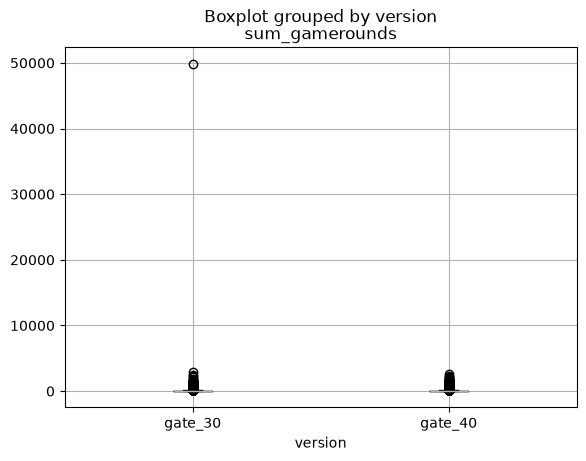

In [3]:
# 이상치 확인

rounds = df["sum_gamerounds"]

display(rounds.describe())                                     # 요약 통계
display(rounds.quantile([0.5, 0.9, 0.99, 0.999, 0.9999]))      # 분위수
display(rounds.nlargest(10))                                   # 상위 10명

df.boxplot(column="sum_gamerounds", by="version")
plt.show()

In [4]:
# 이상치 제거

df_clean = df[df["sum_gamerounds"] < 10000]

print("제거 전:", df.shape)
print("제거 후:", df_clean.shape)
print("제거 후 최댓값:", df_clean["sum_gamerounds"].max())

제거 전: (90189, 5)
제거 후: (90188, 5)
제거 후 최댓값: 2961


> **이상치 제거:** 게임 판수를 크기순으로 정렬했을 때 2위(2,961판)보다 17배 많은 49,854판 유저 1명이 다른 값들과 동떨어져 있어, 정상적인 플레이로 보기 어려워 제거했다.

## 2. 질문과 가설

**비즈니스 질문:** 게이트를 30레벨(gate_30, 기존)에서 40레벨(gate_40, 변경)로 옮기면 유저 리텐션이 달라지는가?

**지표**
- 주 지표: 7일 리텐션 (설치 7일 후에도 게임을 하는 유저 비율)
- 보조 지표: 1일 리텐션 (설치 1일 후에도 게임을 하는 유저 비율)

7일 리텐션을 주 지표로 정한 이유: 장기적으로 남는 유저가 매출과 직결되기 때문이다.

**가설 (7일 리텐션)**
- H0: gate_30과 gate_40의 7일 리텐션은 같다
- H1: gate_30과 gate_40의 7일 리텐션은 다르다

**가설 (1일 리텐션)**
- H0: gate_30과 gate_40의 1일 리텐션은 같다
- H1: gate_30과 gate_40의 1일 리텐션은 다르다

**판단 기준:** 유의수준 α = 0.05, 양측 검정

( *보조 지표는 참고용* )

## 3. 검정 선택

**선택한 검정:** 두 비율 z-검정 (확인용으로 카이제곱 검정 병행)

**선택 이유**
- 지표(리텐션)가 True/False인 이진 변수라서 평균이 아닌 비율을 비교한다.
- gate_30과 gate_40은 서로 다른 유저로 구성된 독립된 두 그룹이다.
- z-검정은 두 비율의 차이를 직접 다루기 때문에 차이의 95% 신뢰구간까지 함께 구할 수 있다.

**전제 조건 확인**
- 독립성: 중복 유저가 없어 각 유저는 한 그룹에만 속한다. ✅
- 표본 크기: 그룹당 4만 명 이상으로 정규분포 근사가 가능하다. ✅

**검정 선택 이유**

나는 **두 비율 z-검정**을 골랐다. 왜냐하면 이번 실험의 성공 지표인 1일·7일 리텐션은 유저가 다시 접속했는지(True/False)를 나타내는 이진 변수여서, 평균이 아니라 재접속한 유저의 비율을 비교해야 하기 때문이다. 비교 집단은 gate_30과 gate_40 두 개이고, 중복 유저가 없어 각 유저는 한 그룹에만 속하는 독립 표본이다. 정규성과 등분산은 연속형 지표를 t-검정으로 비교할 때 확인하는 조건이라 이번 분석에는 해당하지 않는다. 대신 비율 검정은 표본이 충분히 커야 정규분포 근사가 성립하는데, 그룹당 4만 명 이상이므로 이 조건을 만족한다. 같은 2×2 비교에서 카이제곱 검정도 동일한 p-value를 주지만, z-검정은 두 비율의 차이를 직접 다루기 때문에 4단계에서 보고할 차이의 95% 신뢰구간까지 자연스럽게 구할 수 있어 주 검정으로 선택했다.

## 4. 선택한 검정 시행

In [5]:
# 검정 함수 만들기

import numpy as np
from scipy.stats import norm, chi2_contingency

def ab_test(data, metric):
    # 그룹 나누기
    a = data[data["version"] == "gate_30"][metric]   # A: 기존
    b = data[data["version"] == "gate_40"][metric]   # B: 변경
    n_a, n_b = len(a), len(b)

    # ① 점추정: 각 그룹 리텐션 비율과 그 차이
    p_a, p_b = a.mean(), b.mean()    # True=1, False=0이라 평균이 곧 비율
    diff = p_b - p_a

    # 두 비율 z-검정 (H0: 두 비율이 같다)
    p_pool = (a.sum() + b.sum()) / (n_a + n_b)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1/n_a + 1/n_b))
    z = diff / se_pool
    p_value = 2 * (1 - norm.cdf(abs(z)))    # 양측 검정

    # ② 95% 신뢰구간: 차이 ± 1.96 × 표준오차
    se = np.sqrt(p_a*(1-p_a)/n_a + p_b*(1-p_b)/n_b)
    ci_low, ci_high = diff - 1.96*se, diff + 1.96*se

    # ③ 효과크기: Cohen's h
    h = 2*np.arcsin(np.sqrt(p_b)) - 2*np.arcsin(np.sqrt(p_a))

    # 확인용: 카이제곱 검정
    chi_p = chi2_contingency(pd.crosstab(data["version"], data[metric]), correction=False)[1]

    return pd.Series({
        "gate_30": p_a, "gate_40": p_b, "차이(40-30)": diff,
        "CI 하한": ci_low, "CI 상한": ci_high,
        "z": z, "p-value": p_value,
        "Cohen's h": h, "카이제곱 p": chi_p
    })

In [6]:
# 보고용 수치: χ², Cramér's V, 상대 차이

for metric in ["retention_7", "retention_1"]:
    table = pd.crosstab(df_clean["version"], df_clean[metric])
    chi2, p, dof, _ = chi2_contingency(table, correction=False)
    n = table.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))

    rate = df_clean.groupby("version")[metric].mean()
    diff = rate["gate_40"] - rate["gate_30"]      # 절대 차이
    rel = diff / rate["gate_30"]                   # 상대 차이

    print(f"[{metric}] gate_30 {rate['gate_30']:.2%} vs gate_40 {rate['gate_40']:.2%}")
    print(f"  {diff*100:+.2f}%p (상대 {rel:+.1%}), χ²({dof}) = {chi2:.2f}, p = {p:.4f}, Cramér's V = {cramers_v:.3f}\n")

[retention_7] gate_30 19.02% vs gate_40 18.20%
  -0.82%p (상대 -4.3%), χ²(1) = 9.97, p = 0.0016, Cramér's V = 0.011

[retention_1] gate_30 44.82% vs gate_40 44.23%
  -0.59%p (상대 -1.3%), χ²(1) = 3.19, p = 0.0739, Cramér's V = 0.006



In [7]:
# 검정 셀 시행 (주지표+보조지표)

result = pd.DataFrame({
    "7일 리텐션(주)": ab_test(df_clean, "retention_7"),
    "1일 리텐션(보조)": ab_test(df_clean, "retention_1")
})
result.round(4)

,7일 리텐션(주),1일 리텐션(보조)
gate_30,0.1902,0.4482
gate_40,0.1820,0.4423
차이(40-30),-0.0082,-0.0059
CI 하한,-0.0133,-0.0124
CI 상한,-0.0031,0.0006
z,-3.1574,-1.7871
p-value,0.0016,0.0739
Cohen's h,-0.0210,-0.0119
카이제곱 p,0.0016,0.0739


## 4-1. 검정 결과

| 3종 세트 | 질문 | 7일 리텐션 (주) | 1일 리텐션 (보조) |
|---|---|---|---|
| ① **점추정** (차이) | 얼마나 차이 나는가 | **−0.82%p** (상대 −4.3%)<br>19.02% → 18.20% | −0.59%p (상대 −1.3%)<br>44.82% → 44.23% |
| ② **95% 신뢰구간** | 그 추정이 얼마나 불확실한가 | **[−1.33, −0.31]%p**<br>구간 전체가 0보다 작다 | [−1.24, +0.06]%p<br>0을 포함한다 |
| ③ **효과 크기** | 그 차이가 큰 차이인가 | **h = −0.021**<br>"작음"(0.2)의 1/10, 매우 작다 | h = −0.012<br>매우 작다 |
| 검정 | | p = .002 → **귀무가설 기각** | p = .074 → 기각할 수 없음 |

*차이 = gate_40 − gate_30. z-검정과 카이제곱 검정의 p-value는 동일하게 나왔다.*

**보고 문장**
- **7일 리텐션:** gate_40의 7일 리텐션이 gate_30보다 낮았다(18.20% vs 19.02%).
  `−0.82%p (상대 −4.3%), 95% CI [−1.33%p, −0.31%p], χ²(1) = 9.97, p = .002, Cramér's V = 0.01`
- **1일 리텐션:** gate_40의 1일 리텐션이 다소 낮았으나 통계적으로 유의하지 않았다(44.23% vs 44.82%).
  `−0.59%p (상대 −1.3%), 95% CI [−1.24%p, +0.06%p], χ²(1) = 3.19, p = .074, Cramér's V = 0.01`

> **해석:** gate_40은 7일 리텐션을 **작지만 일관되게 낮춘다.** ① 0.82%p 낮아졌고, ② 가장 좋게 봐도 0.31%p는 낮아지며, ③ 그 크기는 매우 작다. 표본이 커서 작은 차이도 검출되었으며, 신규 유저 10만 명 기준 약 820명이 덜 남는 셈이다. 1일 리텐션은 "차이가 없다"가 아니라 "확인하지 못했다"이며,이 표본으로는 약 0.93%p보다 작은 효과를 배제할 수 없기 때문이다 (5. 검정력 분석 참고.)

## 5. 한걸음 더 (A. 이 실험은 효과를 잡을 ’힘’이 있었나)

In [8]:
# 80% 검정력으로 +1%p를 잡으려면 그룹당 몇 명?

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

power = NormalIndPower()
n_30 = (df_clean["version"] == "gate_30").sum()
n_40 = (df_clean["version"] == "gate_40").sum()

for metric in ["retention_7", "retention_1"]:
    base = df_clean[df_clean["version"] == "gate_30"][metric].mean()   # 기존 리텐션
    h = proportion_effectsize(base + 0.01, base)                        # +1%p를 Cohen's h로 변환

    # effect_size를 주고 nobs1을 비워두면 → 필요한 인원을 계산
    n_need = power.solve_power(effect_size=h, alpha=0.05, power=0.8,
                               ratio=1, alternative="two-sided")

    print(f"[{metric}] 기준 리텐션 {base:.2%} → {base+0.01:.2%}")
    print(f"  Cohen's h = {h:.4f}, 필요한 인원: 그룹당 {np.ceil(n_need):,.0f}명 (현재 {n_30:,}명)\n")

[retention_7] 기준 리텐션 19.02% → 20.02%
  Cohen's h = 0.0252, 필요한 인원: 그룹당 24,656명 (현재 44,699명)

[retention_1] 기준 리텐션 44.82% → 45.82%
  Cohen's h = 0.0201, 필요한 인원: 그룹당 38,900명 (현재 44,699명)



In [9]:
# MDE: 지금 표본으로 잡을 수 있는 가장 작은 효과

for metric in ["retention_7", "retention_1"]:
    base = df_clean[df_clean["version"] == "gate_30"][metric].mean()

    # nobs1을 주고 effect_size를 비워두면 → 잡을 수 있는 최소 효과를 계산
    mde_h = power.solve_power(nobs1=n_30, ratio=n_40/n_30, alpha=0.05,
                              power=0.8, alternative="two-sided")

    # Cohen's h를 다시 %p로 바꾸기
    mde_p = np.sin(np.arcsin(np.sqrt(base)) + mde_h/2)**2 - base

    print(f"[{metric}] MDE: Cohen's h = {mde_h:.4f} → 약 {mde_p*100:.2f}%p")

[retention_7] MDE: Cohen's h = 0.0187 → 약 0.74%p
[retention_1] MDE: Cohen's h = 0.0187 → 약 0.93%p



**필요 표본 크기 (α = 0.05, 검정력 80%, +1%p 효과)**
- 7일 리텐션(19.0% → 20.0%): 그룹당 24,656명 필요 → 현재 44,699명으로 충분하다.
- 1일 리텐션(44.8% → 45.8%): 그룹당 38,900명 필요 → 현재 44,699명으로 충분하다.

**MDE (최소 탐지 가능 효과)**
- 7일 리텐션: 약 0.74%p
- 1일 리텐션: 약 0.93%p

> **결론:** 우리 표본은 7일 리텐션에서 약 0.74%p, 1일 리텐션에서 약 0.93%p 이상의 효과만 볼 수 있었다.

> **B, C, D를 선택하지 않은 이유:** C(세그먼트 분석)는 데이터에 요일·시간대 열이 없어 적용할 수 없고, D(비용 분석)는 매출 데이터가 없으며 결론이 이미 "도입하지 않음"이라 계산의 실익이 적다. A는 4단계 결과(특히 1일 리텐션의 비유의 결과)를 해석하는 데 직접 연결되어 선택했다.

## 6. 최종 보고서 

> **결정: 보류 (gate_40을 모든 유저에게 적용하지 않고, 게이트를 기존처럼 30레벨에 유지한다)**
> 
> - **출시하지 않는 이유:** 주 지표인 7일 리텐션이 gate_40에서 0.82%p(상대 4.3%) 낮아졌고, 신뢰구간 전체가 0보다 작아 나빠지는 방향이 분명하다.
> - **데이터를 더 모으지 않는 이유:** 주 지표에서 이미 유의한 결과를 얻었고 신뢰구간 전체가 0보다 작아, 지금 표본으로 판단하기에 충분하다.

---

### 1) 질문과 가설: 무엇을 알고 싶었나

**질문:** 게이트를 30레벨(gate_30, 기존)에서 40레벨(gate_40, 변경)로 옮기면 유저 리텐션이 달라지는가?

| 구분 | 지표 | H0 | H1 |
|---|---|---|---|
| 주 지표 | 7일 리텐션 | 두 그룹의 7일 리텐션은 같다 | 다르다 |
| 보조 지표 | 1일 리텐션 | 두 그룹의 1일 리텐션은 같다 | 다르다 |

- 유의수준 α = 0.05, 양측 검정
- 지표를 두 개 검정했지만 결론은 사전에 정한 주 지표(7일 리텐션)로 내린다. Bonferroni 보정(α = 0.05 ÷ 2 = 0.025)을 적용해도 7일 리텐션의 p = .002는 유의하다.
- 7일 리텐션을 주 지표로 정한 이유: 장기적으로 남는 유저가 매출과 직결되기 때문이다.
- 가설과 판단 기준은 그룹별 리텐션을 계산하기 전에 정했고, 결과와 관계없이 끝까지 유지했다.

### 2) 데이터 위생 점검: 무엇을 어떻게 정제했나

| 점검 항목 | 결과 | 조치 |
|---|---|---|
| 크기 | 90,189행 × 5열 | - |
| 결측치 | 0개 | 없음 |
| 중복 유저 | 0명 | 없음 |
| 그룹 비율 (SRM) | 49.6 : 50.4, p = .009 | 실무 기준(p < .001)에서 문제없고 차이 1% 미만이라 진행 |
| 이상치 | 49,854판 유저 1명 (2위 2,961판의 17배) | **제거** |
| 0판 유저 | 3,994명 | 설치 후 플레이하지 않은 정상 행동으로 보고 유지 |

- 이상치 판단 근거: 분위수로 보면 상위 0.01%도 약 2,000판인데 이 유저만 동떨어져 있었다.
- IQR 규칙은 분포가 오른쪽으로 크게 치우쳐 있어 정상 유저 11%(120판 초과)를 이상치로 잡기 때문에 사용하지 않았다.
- **최종 분석 대상: 90,188명** (gate_30: 44,699명 / gate_40: 45,489명)

### 3) 검정 선택 근거: 왜 그 검정인가

| 질문 | 답 |
|---|---|
| 성공 지표가 비율인가, 연속형인가? | **비율** (재접속 여부 True/False) |
| 비교 집단이 2개인가, 3개 이상인가? | **2개** (gate_30, gate_40, 독립 표본) |
| 정규성·등분산은 그럴듯한가? | **해당 없음** (연속형 지표가 아님). 대신 그룹당 4만 명 이상으로 정규분포 근사 가능 |

나는 **두 비율 z-검정**을 골랐다. 왜냐하면 리텐션은 이진 변수라 비율을 비교해야 하고, 서로 독립인 두 그룹을 비교하며, 표본이 충분히 커서 정규분포 근사가 성립하기 때문이다. 같은 결과를 주는 카이제곱 검정 대신 z-검정을 주 검정으로 쓴 이유는, 두 비율의 **차이**를 직접 다뤄 95% 신뢰구간까지 구할 수 있기 때문이다. (자세한 근거는 3. 검정 선택 참고)

### 4) 결과: 점추정 · 신뢰구간 · 효과크기

| 지표 | gate_30 | gate_40 | 차이 (상대) | 95% CI | p | Cohen's h | Cramér's V |
|---|---|---|---|---|---|---|---|
| **7일 리텐션 (주)** | 19.02% | 18.20% | **−0.82%p (−4.3%)** | [−1.33, −0.31]%p | **.002** | −0.021 | 0.01 |
| 1일 리텐션 (보조) | 44.82% | 44.23% | −0.59%p (−1.3%) | [−1.24, +0.06]%p | .074 | −0.012 | 0.01 |

**7일 리텐션 (주 지표)**
gate_40의 7일 리텐션이 gate_30보다 낮았다(18.20% vs 19.02%).
`−0.82%p (상대 −4.3%), 95% CI [−1.33%p, −0.31%p], χ²(1) = 9.97, p = .002, Cramér's V = 0.01`

**1일 리텐션 (보조 지표)**
gate_40의 1일 리텐션이 gate_30보다 다소 낮았으나 통계적으로 유의하지 않았다(44.23% vs 44.82%).
`−0.59%p (상대 −1.3%), 95% CI [−1.24%p, +0.06%p], χ²(1) = 3.19, p = .074, Cramér's V = 0.01`

**검정력 분석 (α = 0.05, 검정력 80%)**

| 지표 | +1%p를 잡는 데 필요한 인원 | 현재 인원 | MDE |
|---|---|---|---|
| 7일 리텐션 | 그룹당 24,656명 | 44,699명 | 0.74%p |
| 1일 리텐션 | 그룹당 38,900명 | 44,699명 | 0.93%p |

**해석**
- **통계적 유의성과 실질적 크기는 다르다.** 7일 리텐션은 p = .002로 유의했지만 효과크기(h = −0.021)는 매우 작다. 표본이 9만 명으로 커서 작은 차이도 검출된 것이다. 따라서 "gate_40이 리텐션을 크게 떨어뜨린다"가 아니라 **"작지만 일관되게 낮춘다"**로 해석해야 한다.
- **그래도 무시할 차이는 아니다.** 신규 유저 10만 명 기준으로 7일 뒤 남는 유저가 약 820명 줄어드는 셈이다.
- **1일 리텐션의 비유의 결과는 "차이 없음"이 아니다.** 이 표본의 MDE는 0.93%p라서 그보다 작은 효과는 배제할 수 없고, 신뢰구간 [−1.24%p, +0.06%p]도 작은 감소 가능성을 포함한다. 방향은 7일 리텐션과 같이 gate_40이 낮았다.

### 5) 의사결정: 보류

**gate_40을 출시하지 않고 기존 gate_30을 유지한다.**

| 선택지 | 판단 | 근거 |
|---|---|---|
| 출시 | ❌ | 주 지표인 7일 리텐션이 유의하게 낮아졌다. 신뢰구간 상한(−0.31%p)까지 마이너스라 좋아질 가능성은 낮다. |
| **보류** | ✅ | 변경으로 얻는 이득이 확인되지 않았고, 효과는 작지만 리텐션을 낮추는 방향이 분명하다. 바꿀 이유가 없는 변경은 적용하지 않는다. |
| 데이터 추가 수집 | ❌ | 주 지표에서 이미 유의한 결과를 얻었고 신뢰구간이 0을 포함하지 않아 판단에 충분하다. 1일 리텐션은 보조 지표이고 방향이 같아, 추가로 모아도 결정이 바뀌기 어렵다. 결과가 유의해질 때까지 표본을 늘리는 것은 peeking에 해당한다. |

### 6) 한계: 이 결론이 기대는 가정, 이 데이터로 알 수 없는 것

**이 결론이 기대는 가정**
- **무작위 배정:** 두 그룹이 무작위로 나뉘어 게이트 위치 외에는 차이가 없다고 가정했다. SRM 검정이 0.05 기준에서는 유의해(p = .009) 배정 과정에 작은 문제가 있었을 가능성을 완전히 배제할 수는 없다.
- **독립성:** 한 유저의 행동이 다른 유저에게 영향을 주지 않는다고 가정했다.
- **이상치 판단:** 49,854판 유저를 기록 오류로 보고 제거했다. 실제 유저였을 가능성도 있지만, 리텐션 비교에 미치는 영향은 1명이라 미미하다.

**이 데이터로 알 수 없는 것**
- **장기 효과:** 리텐션이 1일·7일만 기록되어 있다. 상대 차이가 1일(−1.3%)보다 7일(−4.3%)에 더 커서 기간이 길어질수록 격차가 벌어질 가능성이 있으나, 확인하려면 30일 리텐션을 주 지표로 정한 후속 실험이 필요하다.
- **매출 영향:** 게이트는 결제와도 연결되지만 매출 데이터가 없어 수익에 미치는 영향은 판단할 수 없다.
- **실제 노출 효과:** 설치 후 한 판도 하지 않은 유저 3,994명처럼 게이트에 도달하지 못한 유저가 포함되어 있다. 게이트를 실제로 경험한 유저만 보면 효과가 더 클 수 있다.
- **원인:** gate_40이 왜 리텐션을 낮추는지(예: 휴식 없이 몰아서 하다 빨리 질린다)는 이 데이터로 설명할 수 없다.